## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the data

In [2]:
path_train ="GiveMeSomeCredit.csv"

data= pd.read_csv(path_train)

print("shape", data.shape)
data.head(10)

shape (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
5,1,1.459344,54,F,3,3,1718.000000,NaN,18,9,0,7,0.0,2
6,1,14.540918,45,F,3,3,1.151865,3726.0,11,0,2,7,3.0,3
7,1,0.915053,48,M,2,1,0.652057,2600.0,8,0,1,7,0.0,3
8,1,1.000000,31,F,2,0,503.000000,NaN,4,7,0,7,0.0,2
9,0,1.445042,38,F,3,0,0.136132,4715.0,5,3,0,7,2.0,0


In [3]:
df=data.copy()

## 3. Understand the structure


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  str    
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  NumberOfTim

In [5]:
df["SEX"] = df["SEX"].map({
    "M": 0,
    "F": 1
})

In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 149724
Number of columns: 14


## 4. Define the target


In [7]:
target = "SeriousDlqin"

print("Target:", target)
print("Unique values:")
print(df[target].unique())

Target: SeriousDlqin
Unique values:
[1 0]


In [8]:
target_summary = pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": df[target].value_counts(normalize=True).mul(100).round(2)
})

target_summary

,Count,Percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


## 5. Duplicate rows

In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)


Number of duplicated rows: 142


In [10]:
df[df.duplicated(keep=False)]


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
30045,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30050,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30067,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30070,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
121347,0,1.0,22,1,1,0,0.0,929.0,1,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149706,0,0.0,42,0,3,0,0.0,NaN,2,0,0,0,0.0,0
149709,0,0.0,79,1,3,0,0.0,NaN,1,0,0,0,NaN,0
149714,0,0.0,23,1,2,0,0.0,NaN,2,0,0,0,0.0,0
149717,0,0.0,59,1,1,0,0.0,NaN,1,0,0,0,0.0,0


## 6. Linear Correlation

In [11]:
corr = df.corr()

corr[target].sort_values(ascending=False)

SeriousDlqin                            1.000000
NumberOfDefault                         0.921535
NumberOfTimes90DaysLate                 0.314557
NumberOfTime30-59DaysPastDueNotWorse    0.274554
NumberOfTime60-89DaysPastDueNotWorse    0.268128
NumberOfDependents                      0.047442
EDUCATION                               0.002214
RevolvingUtilizationOfUnsecuredLines   -0.001625
SEX                                    -0.002724
NumberRealEstateLoansOrLines           -0.003895
DebtRatio                              -0.008778
MonthlyIncome                          -0.023343
NumberOfOpenCreditLinesAndLoans        -0.024219
age                                    -0.112966
Name: SeriousDlqin, dtype: float64

## 7. Target Leakage

In [12]:
print(df[["NumberOfDefault", target]].head(20))


    NumberOfDefault  SeriousDlqin
0                 1             1
1                 0             0
2                 0             0
3                 2             1
4                 1             1
5                 2             1
6                 3             1
7                 3             1
8                 2             1
9                 0             0
10                0             0
11                0             0
12                0             0
13                0             0
14                3             1
15                1             1
16                2             1
17                0             0
18                2             1
19                2             1


In [13]:
df = df.drop(columns=["NumberOfDefault"])

print("Leaked feature removed.")

Leaked feature removed.


## 8. Data validation: impossible value


In [14]:
print("Age < 18:", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum())
print("MonthlyIncome < 0:", (df["MonthlyIncome"] < 0).sum())
print("NumberOfTimes90DaysLate < 0:", (df["NumberOfTimes90DaysLate"] < 0).sum())
print("NumberRealEstateLoansOrLines < 0:", (df["NumberRealEstateLoansOrLines"] < 0).sum())

Age < 18: 1
Age > 100: 13
MonthlyIncome < 0: 0
NumberOfTimes90DaysLate < 0: 0
NumberRealEstateLoansOrLines < 0: 0


In [15]:
df = df[(df["age"] >= 18) & (df["age"] <= 100)]

## 9. Train-Test Split

In [16]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (104797, 12)
X_test : (44913, 12)
y_train: (104797,)
y_test : (44913,)


In [17]:
print("Overall:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nTrain:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Overall:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Train:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Test:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64


In [18]:
train_df = X_train.copy()
train_df[target] = y_train

print("Train dataframe shape:", train_df.shape)
train_df.head()

Train dataframe shape: (104797, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
134668,0.203223,60,1,2,0,1600.000000,NaN,8,0,1,0,0.0,0
119703,1.000000,24,0,3,0,0.100074,1358.0,3,0,0,0,0.0,0
37115,0.200152,49,0,1,0,0.224416,12917.0,8,0,1,0,0.0,0
141624,0.025735,78,1,1,0,347.000000,NaN,7,0,0,0,0.0,0
139483,0.133169,29,0,3,0,723.000000,NaN,5,0,0,0,0.0,0


In [19]:
test_df = X_test.copy()
test_df[target] = y_test

print("Train dataframe shape:", test_df.shape)
test_df.head()

Train dataframe shape: (44913, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
76820,0.021663,61,1,3,0,0.500453,5516.0,8,0,2,0,0.0,0
135401,0.000000,62,1,3,0,1461.000000,NaN,14,0,1,0,0.0,0
5324,0.060561,39,1,3,0,0.198144,12500.0,8,0,1,1,2.0,0
90486,0.824374,30,0,2,0,0.100439,4330.0,4,0,0,0,0.0,0
43461,1.000000,41,1,1,0,0.023712,10500.0,1,0,1,0,2.0,1


## 10. Missing value

In [20]:
missing_train = pd.DataFrame({
    "Missing_Count": train_df.isnull().sum(),
    "Missing_Percent": (
        train_df.isnull().mean().mul(100).round(2)
    )
})

missing_train = missing_train.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_train

,Missing_Count,Missing_Percent
MonthlyIncome,20723,19.77
NumberOfDependents,2767,2.64
SEX,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
EDUCATION,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
DebtRatio,0,0.00
NumberOfTimes90DaysLate,0,0.00


In [21]:
train_df.groupby(
    train_df["MonthlyIncome"].isna()
)["SeriousDlqin"].mean()

MonthlyIncome
False    0.068761
True     0.054722
Name: SeriousDlqin, dtype: float64

In [22]:
train_df.groupby(
    train_df["NumberOfDependents"].isna()
)["SeriousDlqin"].mean()

NumberOfDependents
False    0.066627
True     0.042284
Name: SeriousDlqin, dtype: float64

In [23]:
# Missing values in Test
missing_test = pd.DataFrame({
    "Missing_Count": test_df.isnull().sum(),
    "Missing_Percent": test_df.isnull().mean().mul(100).round(2)
})

missing_test = missing_test.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_test

,Missing_Count,Missing_Percent
MonthlyIncome,8877,19.76
NumberOfDependents,1123,2.50
SEX,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
EDUCATION,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
DebtRatio,0,0.00
NumberOfTimes90DaysLate,0,0.00


In [24]:
# Train
train_df["MonthlyIncome_missing"] = (
    train_df["MonthlyIncome"].isna().astype(int)
)

# Test
test_df["MonthlyIncome_missing"] = (
    test_df["MonthlyIncome"].isna().astype(int)
)

In [25]:
income_median = train_df["MonthlyIncome"].median()

train_df["MonthlyIncome"] = train_df["MonthlyIncome"].fillna(
    income_median
)

test_df["MonthlyIncome"] = test_df["MonthlyIncome"].fillna(
    income_median
)

In [26]:
dependents_median = train_df["NumberOfDependents"].median()

train_df["NumberOfDependents"] = train_df[
    "NumberOfDependents"
].fillna(dependents_median)

test_df["NumberOfDependents"] = test_df[
    "NumberOfDependents"
].fillna(dependents_median)

 ## 11. Outlier analysis

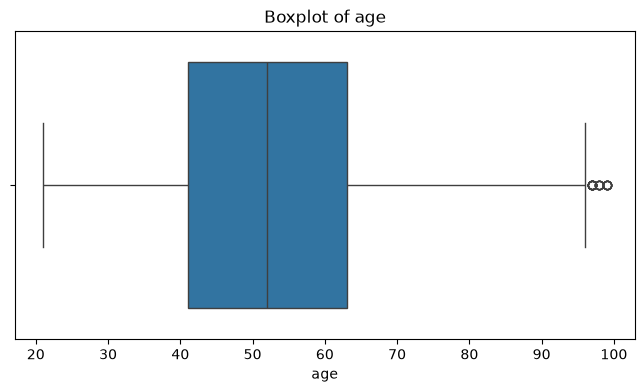

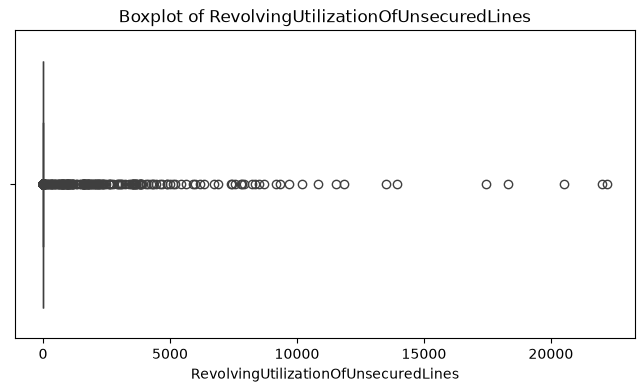

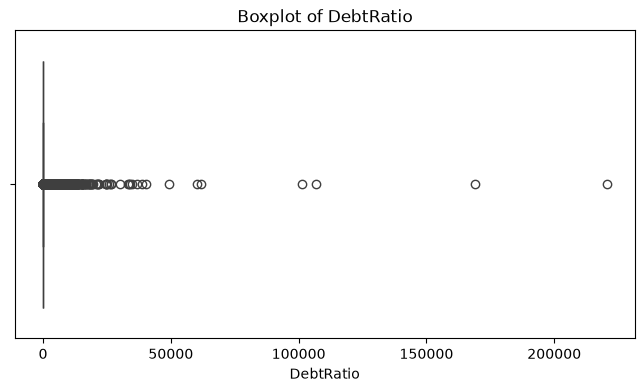

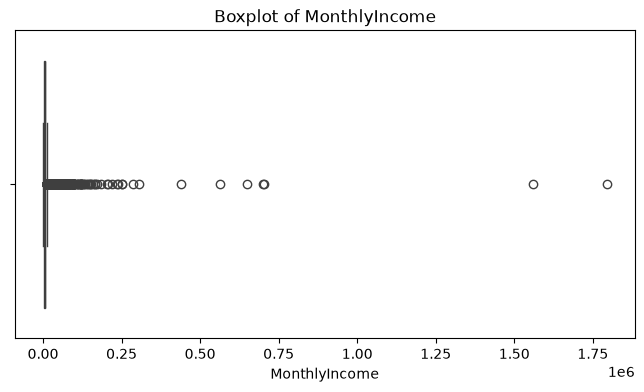

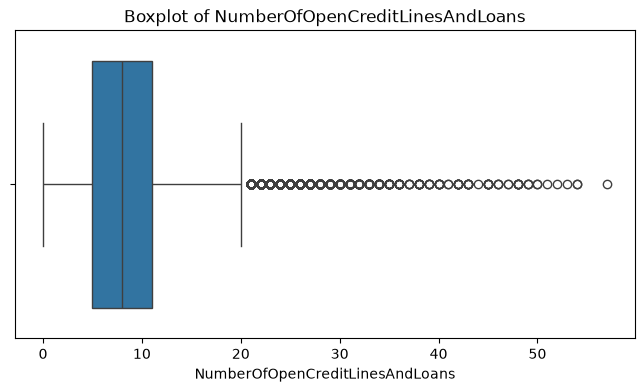

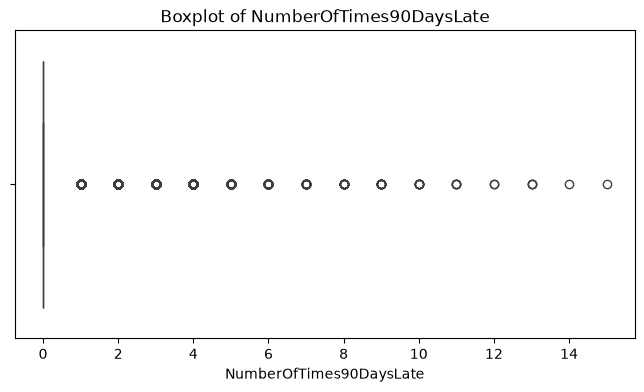

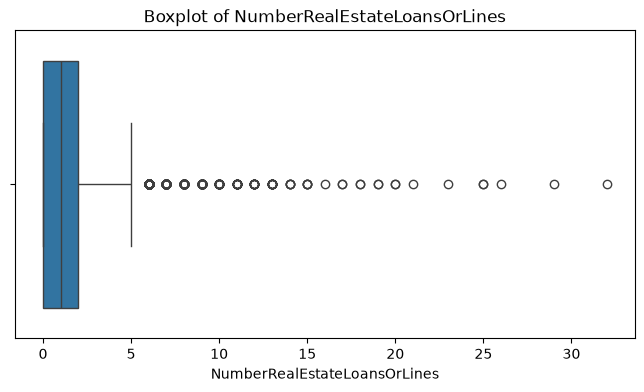

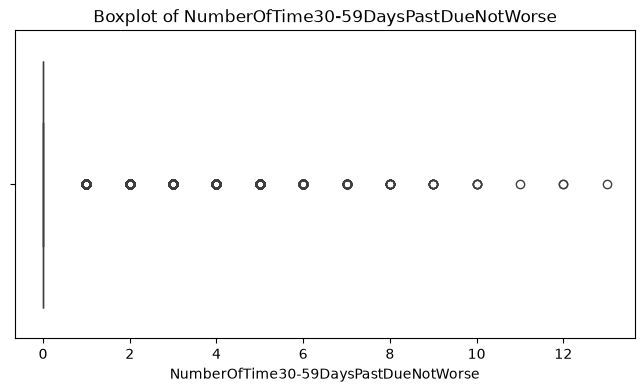

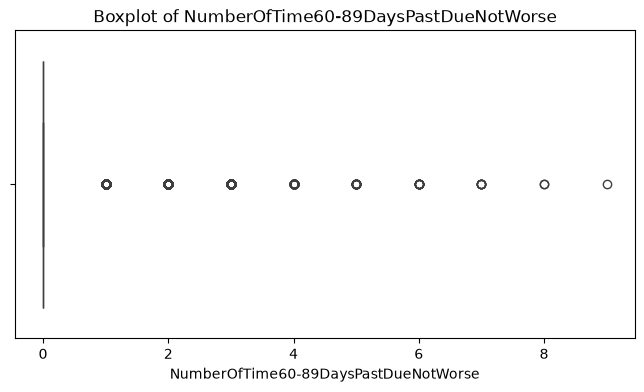

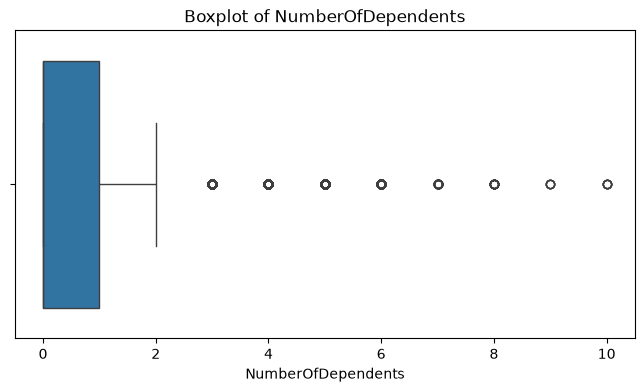

In [27]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [28]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df["Is_Outlier"] = False

outlier_report = []

for col in numeric_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    col_outlier = (
        (train_df[col] < lower) |
        (train_df[col] > upper)
    )

    train_df["Is_Outlier"] = (
        train_df["Is_Outlier"] |
        col_outlier
    )

    count = ((train_df[col] < lower) | (train_df[col] > upper)).sum()

    outlier_report.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Candidate_Outliers": count,
        "Outlier_Percent": round(count / len(train_df) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_report)
outlier_report.sort_values("Outlier_Percent", ascending=False)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Candidate_Outliers,Outlier_Percent
2,DebtRatio,0.175977,0.864820,0.688843,-0.857287,1.898084,21865,20.86
7,NumberOfTime30-59DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,16510,15.75
9,NumberOfDependents,0.000000,1.000000,1.000000,-1.500000,2.500000,9337,8.91
3,MonthlyIncome,3923.000000,7420.000000,3497.000000,-1322.500000,12665.500000,6367,6.08
5,NumberOfTimes90DaysLate,0.000000,0.000000,0.000000,0.000000,0.000000,5652,5.39
8,NumberOfTime60-89DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,5134,4.90
4,NumberOfOpenCreditLinesAndLoans,5.000000,11.000000,6.000000,-4.000000,20.000000,2752,2.63
1,RevolvingUtilizationOfUnsecuredLines,0.029924,0.555344,0.525421,-0.758207,1.343475,542,0.52
6,NumberRealEstateLoansOrLines,0.000000,2.000000,2.000000,-3.000000,5.000000,543,0.52
0,age,41.000000,63.000000,22.000000,8.000000,96.000000,21,0.02


In [29]:
outlier_distribution = (
    train_df[train_df["Is_Outlier"]]["SeriousDlqin"]
    .value_counts()
    .sort_index()
)

print(outlier_distribution)

SeriousDlqin
0    45783
1     5424
Name: count, dtype: int64


## 12. Univariate relationship with target


In [30]:
features_to_compare = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df.groupby(target)[features_to_compare].mean().T

SeriousDlqin,0,1
age,52.785190,46.061171
RevolvingUtilizationOfUnsecuredLines,6.185745,6.001989
DebtRatio,352.223284,305.816230
MonthlyIncome,6447.125958,5644.865076
NumberOfOpenCreditLinesAndLoans,8.502452,7.946638
NumberOfTimes90DaysLate,0.049723,0.672451
NumberRealEstateLoansOrLines,1.021179,0.993926
NumberOfTime30-59DaysPastDueNotWorse,0.192936,0.977440
NumberOfTime60-89DaysPastDueNotWorse,0.041192,0.402025
NumberOfDependents,0.724372,0.941287


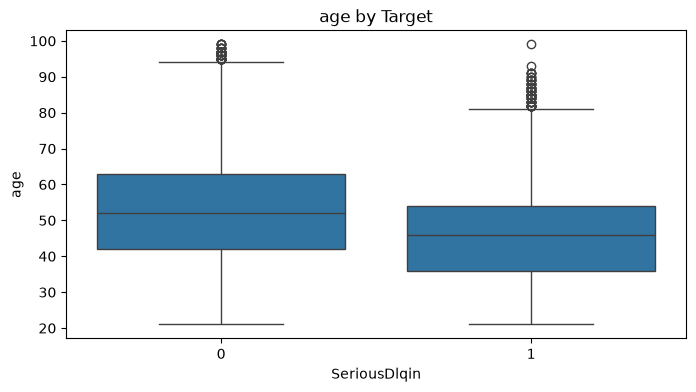

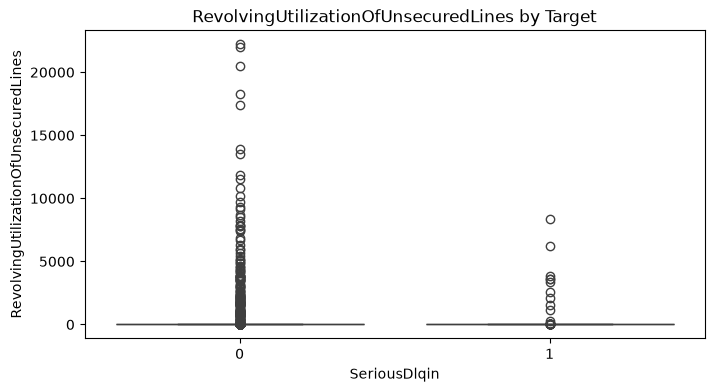

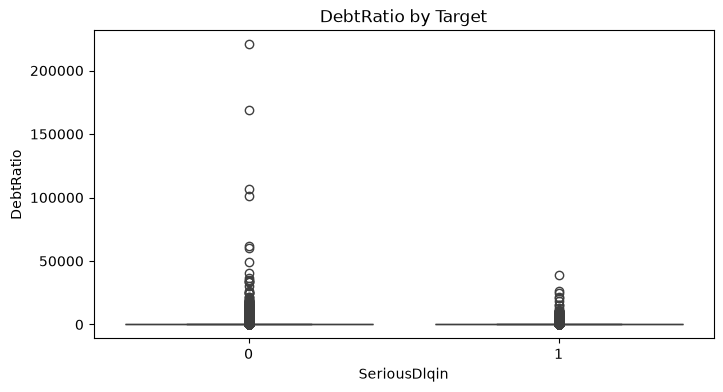

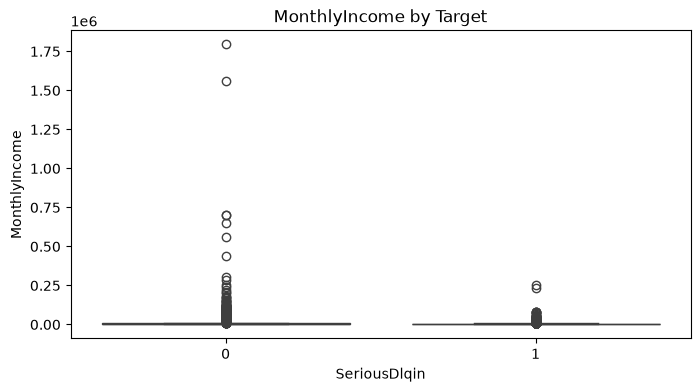

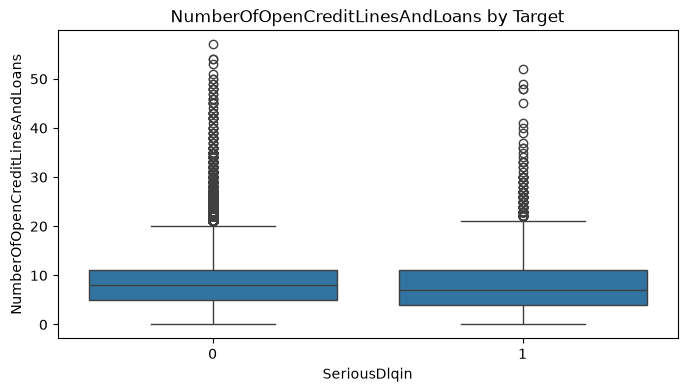

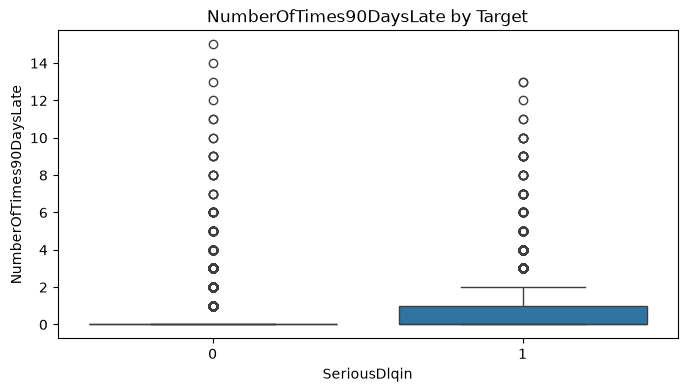

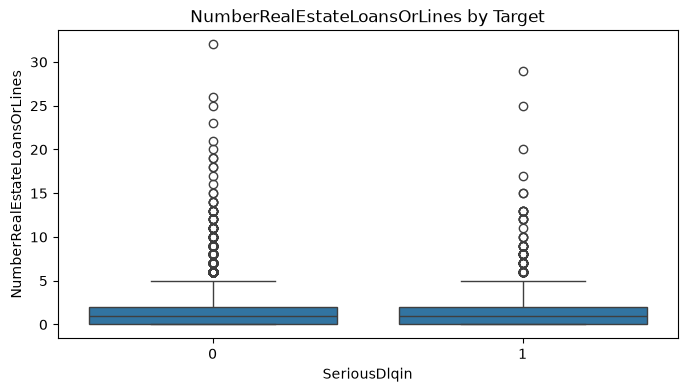

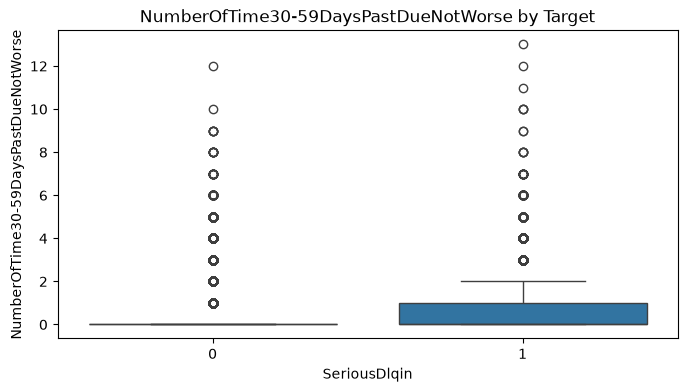

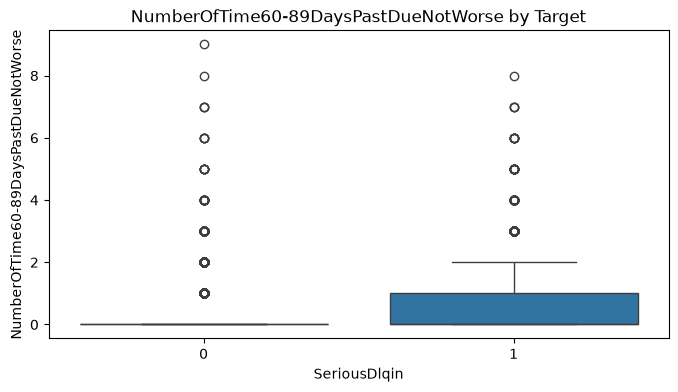

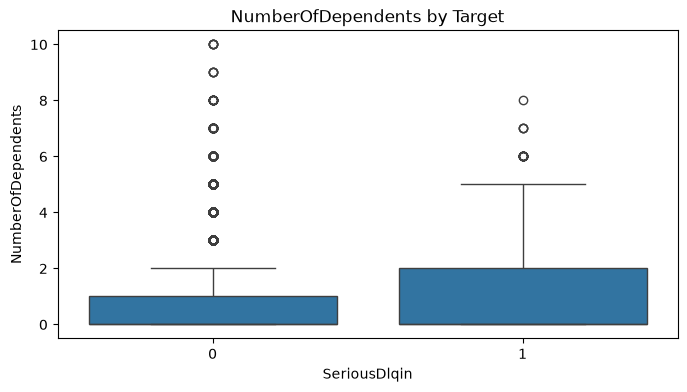

In [31]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=train_df, x=target, y=col)
    plt.title(f"{col} by Target")
    plt.show()

## 13. Categorical analysis

In [32]:
# Check the new categorical features
print(train_df["SEX"].value_counts().sort_index())
print()
print(train_df["EDUCATION"].value_counts().sort_index())

SEX
0    41808
1    62989
Name: count, dtype: int64

EDUCATION
1    26275
2    36528
3    36724
4     5270
Name: count, dtype: int64


In [33]:
sex_risk = train_df.groupby("SEX")[target].agg(
    Customers="size",
    Bad_Rate="mean"
)
sex_risk["Bad_Rate"] *= 100
sex_risk

,Customers,Bad_Rate
SEX,,
0,41808,6.580080
1,62989,6.610678


In [34]:
education_risk = df.groupby("EDUCATION")[target].agg(
    Customers="size",
    Bad_Rate="mean"
)
education_risk["Bad_Rate"] *= 100
education_risk

,Customers,Bad_Rate
EDUCATION,,
1,37561,6.440191
2,52178,6.713557
3,52482,6.569872
4,7489,6.783282


## 14. Feature Engineering

In [35]:
train_df["TotalPastDue"] = (
    train_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + train_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + train_df["NumberOfTimes90DaysLate"]
)

train_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
134668,0,0,0,0
119703,0,0,0,0
37115,0,0,0,0
141624,0,0,0,0
139483,0,0,0,0


In [36]:
test_df["TotalPastDue"] = (
    test_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + test_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + test_df["NumberOfTimes90DaysLate"]
)

test_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
76820,0,0,0,0
135401,0,0,0,0
5324,0,1,0,1
90486,0,0,0,0
43461,0,0,0,0


In [37]:
train_df["Has90DaysLate"] = (train_df["NumberOfTimes90DaysLate"] > 0).astype(int)

train_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    99145
1     5652
Name: count, dtype: int64

In [38]:
test_df["Has90DaysLate"] = (test_df["NumberOfTimes90DaysLate"] > 0).astype(int)

test_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    42497
1     2416
Name: count, dtype: int64

In [39]:
pd.crosstab(
    train_df["Has90DaysLate"],
    train_df[target],
    normalize="index"
).round(3)

SeriousDlqin,0,1
Has90DaysLate,,
0,0.954,0.046
1,0.581,0.419


In [40]:
def get_worst_delay_status(row):
    if row["NumberOfTimes90DaysLate"] > 0:
        return 3
    elif row["NumberOfTime60-89DaysPastDueNotWorse"] > 0:
        return 2
    elif row["NumberOfTime30-59DaysPastDueNotWorse"] > 0:
        return 1
    else:
        return 0


train_df["WorstDelayStatus"] = train_df.apply(get_worst_delay_status, axis=1)
test_df["WorstDelayStatus"] = test_df.apply(get_worst_delay_status, axis=1)

## 15. Binning

In [41]:
bins = [0, 29, 39, 49, 59, 69, np.inf]
labels = ["<30", "30-39", "40-49", "50-59", "60-69", "70+"]

train_df["AgeGroup"] = pd.cut(
    train_df["age"],
    bins=bins,
    labels=labels
)

train_df["AgeGroup"].value_counts().sort_index()

AgeGroup
<30       6103
30-39    16157
40-49    23946
50-59    24736
60-69    20305
70+      13550
Name: count, dtype: int64

In [42]:
_, bins = pd.qcut(
    train_df["DebtRatio"],
    q=5,
    retbins=True,
    duplicates="drop"
)

train_df["DebtRatioGroup"] = pd.cut(
    train_df["DebtRatio"],
    bins=bins
)

## 16. WOE and Information Value


In [43]:
woe_table = train_df.groupby(
    "AgeGroup",
    observed=False
)[target].agg(
    Total="size",
    Bad="sum"
)

woe_table["Good"] = woe_table["Total"] - woe_table["Bad"]

woe_table

,Total,Bad,Good
AgeGroup,,,
<30,6103,682,5421
30-39,16157,1610,14547
40-49,23946,1992,21954
50-59,24736,1592,23144
60-69,20305,723,19582
70+,13550,316,13234


In [44]:
woe_table["Bad_Dist"] = (
    woe_table["Bad"] / woe_table["Bad"].sum()
)

woe_table["Good_Dist"] = (
    woe_table["Good"] / woe_table["Good"].sum()
)

In [45]:
woe_table["WOE"] = np.log(
    woe_table["Good_Dist"] /
    woe_table["Bad_Dist"]
)

woe_table["IV"] = (
    woe_table["Good_Dist"] -
    woe_table["Bad_Dist"]
) * woe_table["WOE"]

In [46]:
IV = woe_table["IV"].sum()

print("IV =", IV)

IV = 0.2379444781393713


In [47]:
train_df.drop(
    columns=["AgeGroup", "DebtRatioGroup"],
    inplace=True
)

## 17. Feature Redundancy

In [48]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",

    # New Features
    "TotalPastDue",
    "Has90DaysLate",
    "WorstDelayStatus",
    "MonthlyIncome_missing"
]

X = train_df[numeric_columns].copy()

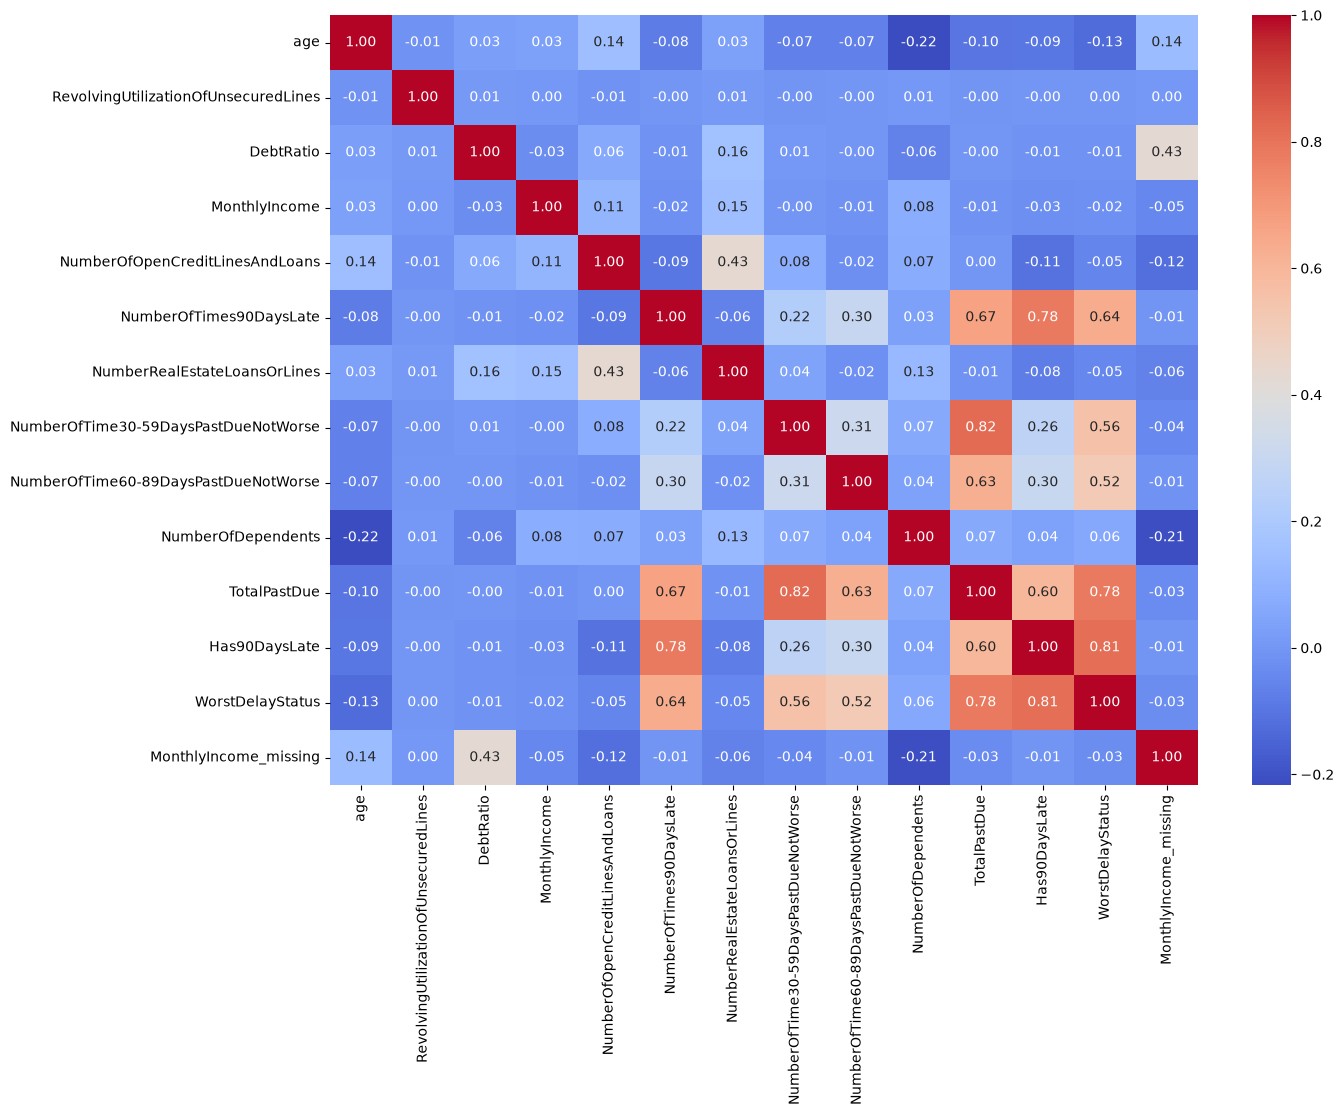

In [49]:
corr_matrix = X.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

## 18. Mutual information

TotalPastDue                            0.048711
WorstDelayStatus                        0.047974
RevolvingUtilizationOfUnsecuredLines    0.036869
NumberOfTimes90DaysLate                 0.032128
Has90DaysLate                           0.031938
NumberOfTime30-59DaysPastDueNotWorse    0.026587
NumberOfTime60-89DaysPastDueNotWorse    0.019390
SEX                                     0.017107
age                                     0.007307
EDUCATION                               0.006537
NumberRealEstateLoansOrLines            0.006051
NumberOfOpenCreditLinesAndLoans         0.005024
MonthlyIncome                           0.005007
DebtRatio                               0.004014
MonthlyIncome_missing                   0.002231
NumberOfDependents                      0.001624
dtype: float64


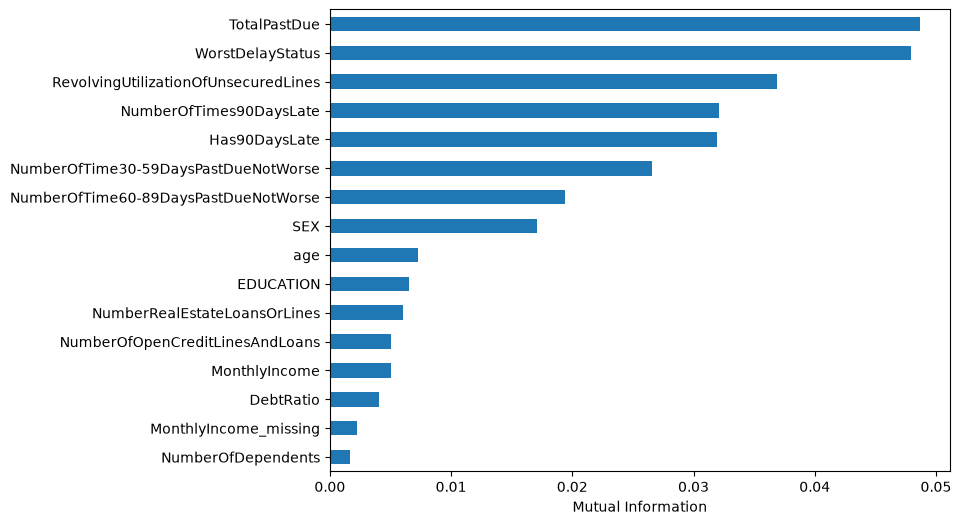

In [50]:
X = train_df.drop(columns=[target, "Is_Outlier"])
y = train_df[target]

mi = mutual_info_classif(X, y, random_state=42)

mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)

print(mi_scores)

mi_scores.sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Mutual Information")
plt.show()

## 19. Train data summary

In [51]:
train_numeric_report = train_df.select_dtypes(include=np.number).describe().T

train_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,104797.0,6.173620,216.960110,0.0,0.029924,0.153382,0.555344,22198.0
age,104797.0,52.341508,14.739044,21.0,41.000000,52.000000,63.000000,99.0
SEX,104797.0,0.601057,0.489683,0.0,0.000000,1.000000,1.000000,1.0
EDUCATION,104797.0,2.200282,0.873039,1.0,1.000000,2.000000,3.000000,4.0
NumberOfTime30-59DaysPastDueNotWorse,104797.0,0.244702,0.695424,0.0,0.000000,0.000000,0.000000,13.0
DebtRatio,104797.0,349.161128,1515.546006,0.0,0.175977,0.366682,0.864820,220516.0
MonthlyIncome,104797.0,6394.189004,10178.917654,0.0,3923.000000,5416.000000,7420.000000,1794060.0
NumberOfOpenCreditLinesAndLoans,104797.0,8.465777,5.129409,0.0,5.000000,8.000000,11.000000,57.0
NumberOfTimes90DaysLate,104797.0,0.090814,0.485827,0.0,0.000000,0.000000,0.000000,15.0
NumberRealEstateLoansOrLines,104797.0,1.019380,1.120560,0.0,0.000000,1.000000,2.000000,32.0


In [52]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
134668,0,0,0
119703,0,0,0
37115,0,0,0
141624,0,0,0
139483,0,0,0


In [53]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df.groupby(target)[new_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.258618,1.487346
TotalPastDue,0.283852,2.051916
Has90DaysLate,0.033540,0.342589


## 20. Test data summary


In [54]:
test_numeric_report = test_df.select_dtypes(include=np.number).describe().T

test_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,44913.0,4.660321,203.115815,0.0,0.029542,0.153936,0.556688,29110.0
age,44913.0,52.281077,14.767130,21.0,41.000000,52.000000,63.000000,99.0
SEX,44913.0,0.602031,0.489485,0.0,0.000000,1.000000,1.000000,1.0
EDUCATION,44913.0,2.198384,0.872026,1.0,1.000000,2.000000,3.000000,4.0
NumberOfTime30-59DaysPastDueNotWorse,44913.0,0.248347,0.703317,0.0,0.000000,0.000000,0.000000,9.0
DebtRatio,44913.0,342.658266,1277.865620,0.0,0.176137,0.368217,0.883749,110952.0
MonthlyIncome,44913.0,6434.311313,10600.336519,0.0,3900.000000,5416.000000,7300.000000,1072500.0
NumberOfOpenCreditLinesAndLoans,44913.0,8.472224,5.153499,0.0,5.000000,8.000000,11.000000,57.0
NumberOfTimes90DaysLate,44913.0,0.089618,0.484859,0.0,0.000000,0.000000,0.000000,17.0
NumberRealEstateLoansOrLines,44913.0,1.020551,1.124151,0.0,0.000000,1.000000,2.000000,25.0


In [55]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

test_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
76820,0,0,0
135401,0,0,0
5324,2,1,0
90486,0,0,0
43461,0,0,0


In [56]:
summary_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate"
]

test_df.groupby(target)[summary_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.267747,1.419507
TotalPastDue,0.291180,1.977050
Has90DaysLate,0.034803,0.322646


In [57]:
train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)